# BiT ResNetV2-50x1 fine-tuning

A third CNN family for the ensemble. `resnetv2_50x1_bit.goog_in21k_ft_in1k` is Google's Big Transfer model (BiT-M): a ResNetV2 with 23.5M parameters, pretrained on ImageNet-21k and fine-tuned on ImageNet-1k. Its normalization differs from our other two members: GroupNorm with weight-standardized convolutions and no BatchNorm, against ConvNeXt's LayerNorm (Exp1) and EfficientNet's BatchNorm (Exp3). Exp1 and Exp3 scored almost the same on the leaderboard but disagreed on 219 test cells, and averaging them gained +0.0075, so a third architecture should again add disagreement. BiT-M uses ImageNet-21k only, which is ImageNet data; the larger BiT-L models use JFT and are not used here.

We follow the Exp3 protocol: the saved folds, 384-pixel letterbox, BCEWithLogitsLoss, fixed 0.25 threshold, checkpoint chosen by held-out-fold macro F1, horizontal-flip augmentation only, effective batch 16, and its own head warm-up before the full fine-tune. Differences:

1. **No BatchNorm to freeze.** BiT has no running statistics, so the `FrozenBatchNormStatistics` callback from Exp3 is not used.
2. **Learning rates between our two earlier runs.** Backbone `3e-5` and head `3e-4`, against `1e-4` and `1e-3` for Exp3 (whose validation loss rose after epoch 4) and `1e-5` and `1e-4` for ConvNeXt. These are untuned guesses.
3. **The classifier is a 1×1 convolution** on the pooled features, which is the same as a linear layer.
4. **Native size 448.** The network is fully convolutional, so we keep 384 for identical preprocessing and a lower cost.

On a Mac GPU a short probe projected about 14 minutes per fine-tune epoch and about 3.5 GB of memory. By default the notebook only checks its inputs. Training, weight download and file creation need explicit flags. The held-out fold defaults to 0; set `STAGE2_VALIDATION_FOLD` to run another one, and the run name follows it. Kaggle upload is always manual.

In [1]:
from __future__ import annotations

import importlib
import json
import os
import platform
import random
import re
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import torch

RUN_TRAINING = True
SMOKE_TEST = False
PROFILE_ONLY = False
BACKUP_TO_DRIVE = os.environ.get('STAGE2_BACKUP_TO_DRIVE', '0') == '1'
DRIVE_FOLDER_NAME = os.environ.get('STAGE2_DRIVE_FOLDER_NAME', 'AI301-stage2')
DRIVE_ROOT = (Path('/content/drive/MyDrive') / DRIVE_FOLDER_NAME).resolve()
ALLOW_WEIGHT_DOWNLOAD = os.environ.get('STAGE2_ALLOW_WEIGHT_DOWNLOAD', '0') == '1'
USE_WANDB = os.environ.get('STAGE2_USE_WANDB', '1') == '1'
REMOVE_RUNTIME_ENV_AFTER_LOAD = os.environ.get('STAGE2_REMOVE_RUNTIME_ENV_AFTER_LOAD', '0') == '1'
WANDB_MODE = 'online'
WANDB_PROJECT = 'ai301-stage2'
BUILD_GRADCAM = True  # Only runs after a completed training run.
BUILD_TEST_PREDICTIONS = True  # Saves test probabilities for ensembling.
BUILD_SUBMISSION = True  # Writes a binary CSV into submissions/ from the saved test probabilities (see the submission cell).
SUBMIT_TO_KAGGLE = False  # No submission API call exists in this notebook.

if not ALLOW_WEIGHT_DOWNLOAD:
    os.environ['HF_HUB_OFFLINE'] = '1'  # Must be set before anything imports huggingface_hub.

MODEL_NAME = 'resnetv2_50x1_bit.goog_in21k_ft_in1k'
SEED = 42
VALIDATION_FOLD = int(os.environ.get('STAGE2_VALIDATION_FOLD', '0'))
RUN_ID = os.environ.get('STAGE2_RUN_ID', f'bit_r50x1_fold{VALIDATION_FOLD}_seed42')
THRESHOLD = 0.25
IMAGE_SIZE = 384
BATCH_SIZE = 8  # About 3.5 GB on a Mac GPU at 384 px; lower it to 4 if a smaller GPU runs out of memory.
EFFECTIVE_BATCH_SIZE = 16
HEAD_ONLY_LR = 1e-3
HEAD_EPOCHS = 8  # Exp3's head curve was still climbing after 3 epochs, so we start with 8.
HEAD_PATIENCE = 3
MAX_EPOCHS = 8
PATIENCE = 3
MAX_RUN_HOURS = 3.0
BACKBONE_LR = 3e-5  # Between ConvNeXt (1e-5) and Exp3 (1e-4); untuned.
HEAD_LR = 3e-4  # Between ConvNeXt (1e-4) and Exp3 (1e-3); untuned.
WEIGHT_DECAY = 1e-2
NUM_WORKERS = 2 if torch.cuda.is_available() else 0
PRECISION = '32-true'

if EFFECTIVE_BATCH_SIZE % BATCH_SIZE:
    raise ValueError('Effective batch size must be divisible by physical batch size.')
if VALIDATION_FOLD not in range(5):
    raise ValueError('STAGE2_VALIDATION_FOLD must be 0-4.')
if PROFILE_ONLY and (not RUN_TRAINING or SMOKE_TEST):
    raise ValueError('Profile-only mode requires training enabled and smoke mode disabled.')
if BACKUP_TO_DRIVE and not RUN_TRAINING:
    raise ValueError('Drive backup is for a training run.')
if not re.fullmatch(r'[A-Za-z0-9][A-Za-z0-9._-]{0,79}', RUN_ID):
    raise ValueError('STAGE2_RUN_ID must be a single, safe run name.')
if not re.fullmatch(r'[A-Za-z0-9][A-Za-z0-9._ -]{0,79}', DRIVE_FOLDER_NAME):
    raise ValueError('STAGE2_DRIVE_FOLDER_NAME must be one folder name (letters, numbers, spaces, dots, underscores or hyphens).')
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print(f'Device: {DEVICE}; training: {RUN_TRAINING}; smoke test: {SMOKE_TEST}; profile only: {PROFILE_ONLY}; Drive backup: {BACKUP_TO_DRIVE}')

Device: mps; training: True; smoke test: False; profile only: False; Drive backup: False


## Same split as before

We reuse the saved seed-42 folds and join by image ID, and check that `folds.csv` is still the original stratified split. Before training, we decode the train and validation images so missing or damaged files fail early. Test images are checked only when test predictions are requested.

Images are fitted into a 384-pixel square and padded with the mean colour, without cropping. The model's native size is 448 pixels; we keep 384 as in the other runs. Training adds horizontal flips as data augmentation; validation and test do not. Normalization comes from the pretrained checkpoint (mean and standard deviation 0.5).

In [2]:
start = Path(os.environ.get('STAGE2_ROOT', Path.cwd())).resolve()
ROOT = next((path for path in (start, *start.parents) if (path / 'folds.csv').is_file() and (path / 'stage2' / 'experiment.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Launch Jupyter from this repository or a subdirectory.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from stage2.experiment import LABEL_COLUMNS, ImageDataset, form_submission, preflight_images, read_csv, score_probabilities, split_rows, verify_saved_stratification, write_probabilities, write_run_record, write_submission
from stage2.train import MultilabelClassifier, freeze_except_classifier, predict_probabilities
from stage2 import finetune
importlib.reload(finetune)  # Colab CLI may reuse a kernel from an earlier run.
from stage2.finetune import DriveRunBackup, FineTuneClassifier, TimedBudgetCheckpoint, copy_verified
from stage2.ensemble import read_probabilities, write_test_probabilities
from stage2.run_records import file_sha256, record_failures
from stage2.diagnostics import TrainingDiagnostics, plot_gradient_flow

run_name = RUN_ID + ('_smoke' if SMOKE_TEST else '')
run_dir = ROOT / 'experiments' / 'exp5' / 'results' / run_name if RUN_TRAINING else None
if run_dir is not None:
    run_dir.mkdir(parents=True, exist_ok=False)
failure_configuration = {'run_id': RUN_ID, 'experiment': '05_bit_resnetv2_50x1', 'fold': VALIDATION_FOLD, 'seed': SEED, 'model_name': MODEL_NAME, 'smoke_test': SMOKE_TEST, 'profile_only': PROFILE_ONLY, 'device': str(DEVICE), 'backbone_lr': BACKBONE_LR, 'head_lr': HEAD_LR, 'head_only_lr': HEAD_ONLY_LR, 'weight_decay': WEIGHT_DECAY, 'max_epochs': MAX_EPOCHS, 'patience': PATIENCE, 'precision': PRECISION, 'physical_batch_size': BATCH_SIZE, 'effective_batch_size': EFFECTIVE_BATCH_SIZE, 'threshold': THRESHOLD, 'image_size': IMAGE_SIZE}
def backup_failure(path: Path) -> None:
    if BACKUP_TO_DRIVE and Path('/content/drive/MyDrive').is_dir() and DRIVE_ROOT.is_relative_to('/content/drive/MyDrive'):
        copy_verified(path, DRIVE_ROOT / '05_bit_resnetv2_50x1' / run_name / 'failure.json')

DATA_DIR = ROOT / 'data'
with record_failures(run_dir, failure_configuration, 'data', backup_failure):
    combination_counts = verify_saved_stratification(DATA_DIR, ROOT / 'folds.csv', SEED)
    train_rows, validation_rows = split_rows(DATA_DIR, ROOT / 'folds.csv', VALIDATION_FOLD)
    if RUN_TRAINING:
        preflight_images(train_rows, DATA_DIR / 'train')
        preflight_images(validation_rows, DATA_DIR / 'train')
validation_targets = np.asarray([[int(row[label]) for label in LABEL_COLUMNS] for row in validation_rows])
print(f'Train {len(train_rows)} / validation {len(validation_rows)} images; named pets in validation:',
      {label: int(validation_targets[:, LABEL_COLUMNS.index(label)].sum()) for label in ('Moris', 'Motya', 'Biatrix')})

Train 9808 / validation 2452 images; named pets in validation: {'Moris': 10, 'Motya': 9, 'Biatrix': 8}


## Connect W&B when fine-tuning starts

Fine-tuning logs online to W&B; the head warm-up is logged to a local CSV only. Supply `WANDB_API_KEY` through the ignored local `.env` or a Colab secret; `WB_API_KEY` also works. The notebook does not print or save the key.

In [3]:
def ensure_wandb_key() -> None:
    key = os.environ.get('WANDB_API_KEY') or os.environ.get('WB_API_KEY')
    env_file = ROOT / '.env'
    if not key and env_file.is_file():
        for line in env_file.read_text().splitlines():
            name, separator, value = line.partition('=')
            if separator and name.strip() in {'WANDB_API_KEY', 'WB_API_KEY'}:
                key = value.strip().strip("\"'")
                if key:
                    break
    if key:
        os.environ['WANDB_API_KEY'] = key
        if REMOVE_RUNTIME_ENV_AFTER_LOAD and env_file.is_file() and ROOT.is_relative_to('/content'):
            env_file.unlink()
            print('Removed the temporary Colab credential file.')
        return
    try:
        from google.colab import userdata
    except ImportError:
        raise RuntimeError('Set WANDB_API_KEY in the repo .env file or environment.') from None
    try:
        secret = userdata.get('WANDB_API_KEY')
    except Exception as error:
        raise RuntimeError('Add WANDB_API_KEY to Colab Secrets and grant this notebook access.') from error
    if not secret:
        raise RuntimeError('The WANDB_API_KEY Colab Secret is empty.')
    os.environ['WANDB_API_KEY'] = secret

if RUN_TRAINING and USE_WANDB and WANDB_MODE == 'online':
    with record_failures(run_dir, failure_configuration, 'credentials', backup_failure):
        ensure_wandb_key()
    print('W&B online credential is available (value hidden).')
else:
    print('W&B credential check skipped until online training is enabled.')

W&B online credential is available (value hidden).


## Load the pretrained network and build the loaders

The pretrained checkpoint comes from timm and needs `STAGE2_ALLOW_WEIGHT_DOWNLOAD=1` the first time. We replace its 1000-way classifier with a five-logit one in the fixed label order (in BiT a 1×1 convolution on the pooled features, which is the same as a linear layer). BCEWithLogitsLoss handles each label independently; sigmoid turns the logits into probabilities for validation and submission formation.

The model name is not pinned to a Hugging Face revision, unlike the ConvNeXt runs. The record stores timm's resolved source and the library versions instead.

In [4]:
if RUN_TRAINING:
    if run_dir is None:
        raise RuntimeError('RUN_TRAINING was changed after the setup cells ran. Restart the kernel and run all cells from the top.')
    if run_name.endswith('_smoke') != SMOKE_TEST:
        raise RuntimeError('SMOKE_TEST was changed after the setup cell ran, so the run folder name is stale. Restart the kernel and run all cells from the top.')
    import timm
    import lightning as L
    from lightning.pytorch.callbacks import EarlyStopping, LearningRateMonitor, ModelCheckpoint
    from lightning.pytorch.loggers import CSVLogger
    from torch.utils.data import DataLoader

    L.seed_everything(SEED, workers=True)
    with record_failures(run_dir, failure_configuration, 'model', backup_failure):
        network = timm.create_model(MODEL_NAME, pretrained=True, num_classes=len(LABEL_COLUMNS))
        preprocessing = timm.data.resolve_model_data_config(network)
    pretrained_source = {key: network.pretrained_cfg.get(key) for key in ('hf_hub_id', 'tag', 'architecture')}
    train_data = ImageDataset(train_rows, DATA_DIR / 'train', IMAGE_SIZE, preprocessing['mean'], preprocessing['std'], horizontal_flip=True)
    validation_data = ImageDataset(validation_rows, DATA_DIR / 'train', IMAGE_SIZE, preprocessing['mean'], preprocessing['std'])
    loader_options = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == 'cuda')
    train_generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(train_data, shuffle=True, generator=train_generator, **loader_options)
    validation_loader = DataLoader(validation_data, shuffle=False, **loader_options)
    _, image, targets = train_data[0]
    assert image.shape == (3, IMAGE_SIZE, IMAGE_SIZE) and targets.shape == (5,)
    print('Pretrained source:', pretrained_source)
    print('Normalization:', preprocessing['mean'], preprocessing['std'])
    print('Parameters:', sum(p.numel() for p in network.parameters()))
else:
    print('Training disabled; no model loaded.')

/Users/allakovalcuk/AI301/deep-learning-assignment2/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Seed set to 42


Pretrained source: {'hf_hub_id': 'timm/resnetv2_50x1_bit.goog_in21k_ft_in1k', 'tag': 'goog_in21k_ft_in1k', 'architecture': 'resnetv2_50x1_bit'}
Normalization: (0.5, 0.5, 0.5) (0.5, 0.5, 0.5)
Parameters: 23510597


## Phase 1: training a new head on the frozen backbone

The backbone stays fixed and only the five-logit classifier trains (AdamW, constant LR `1e-3`). The best head by held-out-fold macro F1 at 0.25 is kept and becomes the starting point of phase 2, the same way Exp0's head started Exp1. The head is trained on the folds other than the held-out one and selected on the held-out fold, so a run for another fold trains its own head.

Smoke mode runs four training and two validation batches; its score is not a result.

In [5]:
if RUN_TRAINING:
    head_epochs = 1 if SMOKE_TEST else HEAD_EPOCHS
    with record_failures(run_dir, failure_configuration, 'head_training', backup_failure):
        freeze_except_classifier(network)
        head_module = MultilabelClassifier(network, HEAD_ONLY_LR, WEIGHT_DECAY, THRESHOLD, frozen_backbone=True)
        head_checkpoint = ModelCheckpoint(dirpath=run_dir / 'head_checkpoints', filename='best', monitor='val_macro_f1', mode='max', save_top_k=1, save_weights_only=True)
        head_callbacks = [head_checkpoint] + ([] if SMOKE_TEST else [EarlyStopping(monitor='val_macro_f1', mode='max', patience=HEAD_PATIENCE)])
        head_trainer = L.Trainer(
            accelerator=DEVICE.type, devices=1, precision=PRECISION, max_epochs=head_epochs,
            accumulate_grad_batches=EFFECTIVE_BATCH_SIZE // BATCH_SIZE, callbacks=head_callbacks,
            logger=CSVLogger(save_dir=run_dir, name='head_curves'),
            limit_train_batches=4 if SMOKE_TEST else 1.0, limit_val_batches=2 if SMOKE_TEST else 1.0,
            num_sanity_val_steps=0, gradient_clip_val=1.0, log_every_n_steps=10, enable_progress_bar=False,
        )
        head_started = time.perf_counter()
        head_trainer.fit(head_module, train_loader, validation_loader)
        head_seconds = time.perf_counter() - head_started
        saved = torch.load(head_checkpoint.best_model_path, map_location='cpu', weights_only=True)['state_dict']
        network.load_state_dict({name.removeprefix('network.'): value for name, value in saved.items()}, strict=True)
        head_path = run_dir / 'head.pt'
        torch.save(network.get_classifier().state_dict(), head_path)
        head_score = float(head_checkpoint.best_model_score)
    print(f'Head warm-up: {head_seconds / 60:.1f} min; best held-out fold macro F1 {head_score:.5f} (not a final result); saved {head_path.name}')
else:
    print('No head training.')

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..
`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..

  | Name    | Type              | Params | Mode  | FLOPs
--------------------------------------------------------------
0 | network | ResNetV2          | 23.5 M | train | 0    
1 | loss_fn | BCEWithLogitsLoss | 0      | train | 0    
--------------------------------------------------------------
10.2 K    Trainable params
23.5 M    Non-trainable params
23.5 M    Total params
94.042    Total estimated model params size (MB)
261       Modules in train mode
0         Modules in eval mode
0         Total 

Head warm-up: 30.3 min; best held-out fold macro F1 0.95361 (not a final result); saved head.pt


## Phase 2: fine-tune the whole network

All parameters train. BiT has no BatchNorm, so there are no running statistics to freeze. AdamW uses backbone LR `3e-5` and head LR `3e-4`, weight decay `0.01` on weights but not on biases or normalization parameters, and a step-based scheduler that warms up over the first epoch and then cosine-decays to 10% of the peak by epoch eight. The physical batch is eight with gradient accumulation to an effective 16, and gradient norm is clipped at 1.0. Early stopping waits three validation epochs.

Three training modes, each with a fresh `STAGE2_RUN_ID`. `STAGE2_SMOKE_TEST=1` (default) checks backward propagation, logging and checkpoint reload on a few batches. `STAGE2_SMOKE_TEST=0` with `STAGE2_PROFILE_ONLY=1` runs one complete timing epoch. Both flags at `0` run the full fine-tune; it stops after epoch one if the projected eight-epoch time exceeds `MAX_RUN_HOURS`. Training needs `STAGE2_RUN_TRAINING=1`.

In [6]:
if RUN_TRAINING:
    drive_backup = None
    with record_failures(run_dir, failure_configuration, 'storage_setup', backup_failure):
        if BACKUP_TO_DRIVE:
            if not ROOT.is_relative_to('/content') or not Path('/content/drive/MyDrive').is_dir():
                raise RuntimeError('Mount Google Drive on this Colab runtime before training.')
            if not DRIVE_ROOT.is_relative_to('/content/drive/MyDrive'):
                raise ValueError('The Drive folder must remain under /content/drive/MyDrive.')
            drive_backup = DriveRunBackup(run_dir, DRIVE_ROOT / '05_bit_resnetv2_50x1' / run_name)
            probe = run_dir / 'drive_probe.txt'
            probe.write_text(f'{run_name} Drive write check\n')
            copy_verified(probe, drive_backup.drive_dir / probe.name)
            print('Drive backup available:', drive_backup.drive_dir)
    for parameter in network.parameters():
        parameter.requires_grad_(True)
    network.train()  # Phase 1 left the network in eval mode; fine-tuning starts in train mode.
    module = FineTuneClassifier(network, BACKBONE_LR, HEAD_LR, WEIGHT_DECAY, THRESHOLD)
    run_configuration = {
        'fold': VALIDATION_FOLD, 'seed': SEED,
        'model': {'name': MODEL_NAME, 'variant': 'standard', 'family': 'bit_resnetv2', 'pretrained_source': pretrained_source,
                  'initial_head_checkpoint': str(head_path.relative_to(ROOT)), 'initial_head_sha256': file_sha256(head_path),
                  'head_warmup': {'optimizer': f'AdamW(lr={HEAD_ONLY_LR}, weight_decay={WEIGHT_DECAY})', 'epochs_completed': head_trainer.fit_loop.epoch_progress.current.completed,
                                  'best_heldout_macro_f1': head_score, 'seconds': head_seconds}},
        'data': {'image_size': IMAGE_SIZE, 'transform': 'mean-colour letterbox, bicubic, checkpoint normalization; train horizontal flip p=0.5', 'fold_file': 'folds.csv', 'fold_sha256': file_sha256(ROOT / 'folds.csv'), 'label_columns': list(LABEL_COLUMNS), 'mean': list(preprocessing['mean']), 'std': list(preprocessing['std'])},
        'training': {'optimizer': f'AdamW(backbone_lr={BACKBONE_LR}, head_lr={HEAD_LR}, weight_decay={WEIGHT_DECAY} except bias/norm, betas=(0.9, 0.999))',
                     'scheduler': 'one epoch step warmup then cosine to 0.1 peak', 'loss': 'BCEWithLogitsLoss', 'max_epochs': MAX_EPOCHS, 'patience': PATIENCE,
                     'physical_batch_size': BATCH_SIZE, 'effective_batch_size': EFFECTIVE_BATCH_SIZE, 'precision': PRECISION,
                     'stage_policy': 'full network and classifier trainable; GroupNorm has no running statistics', 'checkpoint_selection': 'best validation macro F1 at 0.25', 'gradient_clip_norm': 1.0},
    }
    checkpoint_options = dict(dirpath=run_dir / 'checkpoints', filename='best', monitor='val_macro_f1', mode='max', save_top_k=1, save_weights_only=True)
    checkpoint = ModelCheckpoint(**checkpoint_options) if SMOKE_TEST else TimedBudgetCheckpoint(**checkpoint_options, maximum_hours=MAX_RUN_HOURS, profile_only=PROFILE_ONLY, epoch_backup=drive_backup.save_epoch if drive_backup else None)
    diagnostics = TrainingDiagnostics(run_dir / 'diagnostics')
    callbacks = [checkpoint, LearningRateMonitor(logging_interval='epoch'), diagnostics]
    if not SMOKE_TEST:
        callbacks.append(EarlyStopping(monitor='val_macro_f1', mode='max', patience=PATIENCE))
    logger = CSVLogger(save_dir=run_dir, name='curves')
    loggers = [logger]
    wandb_logger = None
    if USE_WANDB:
        with record_failures(run_dir, failure_configuration, 'telemetry_setup', backup_failure):
            from lightning.pytorch.loggers import WandbLogger
            wandb_logger = WandbLogger(project=WANDB_PROJECT, name=run_name, save_dir=str(run_dir), offline=False, log_model=False)
            wandb_logger.log_hyperparams({
                'model': MODEL_NAME, 'fold': VALIDATION_FOLD, 'seed': SEED, 'image_size': IMAGE_SIZE, 'batch_size': BATCH_SIZE,
                'effective_batch_size': EFFECTIVE_BATCH_SIZE, 'backbone_lr': BACKBONE_LR, 'head_lr': HEAD_LR, 'head_only_lr': HEAD_ONLY_LR,
                'weight_decay': WEIGHT_DECAY, 'scheduler': 'one-epoch warmup then cosine to 0.1 peak', 'threshold': THRESHOLD,
                'smoke_test': SMOKE_TEST, 'profile_only': PROFILE_ONLY, 'precision': PRECISION, 'runtime_gate_hours': MAX_RUN_HOURS,
                'max_epochs': MAX_EPOCHS, 'normalization': 'GroupNorm with weight standardization', 'drive_backup': BACKUP_TO_DRIVE,
            })
            wandb_logger.watch(module.network.get_classifier(), log='gradients', log_freq=50, log_graph=False)
            print('W&B run:', wandb_logger.experiment.url)
            loggers.append(wandb_logger)
    with record_failures(run_dir, failure_configuration, 'trainer_setup', backup_failure):
        trainer = L.Trainer(
            accelerator=DEVICE.type, devices=1, precision=PRECISION, max_epochs=1 if SMOKE_TEST else MAX_EPOCHS,
            accumulate_grad_batches=EFFECTIVE_BATCH_SIZE // BATCH_SIZE, callbacks=callbacks, logger=loggers,
            limit_train_batches=8 if SMOKE_TEST else 1.0, limit_val_batches=4 if SMOKE_TEST else 1.0,
            num_sanity_val_steps=0, gradient_clip_val=1.0, log_every_n_steps=10, enable_progress_bar=False,
        )
    if DEVICE.type == 'cuda':
        torch.cuda.reset_peak_memory_stats()
    L.seed_everything(SEED, workers=True)
    started = time.perf_counter()
    with record_failures(run_dir, failure_configuration, 'training', backup_failure):
        try:
            trainer.fit(module, train_loader, validation_loader)
        finally:
            if wandb_logger is not None:
                wandb_logger.experiment.finish()
    training_seconds = time.perf_counter() - started
    if SMOKE_TEST:
        if not checkpoint.best_model_path:
            raise RuntimeError('Smoke run produced no checkpoint.')
        restored = FineTuneClassifier.load_from_checkpoint(
            checkpoint.best_model_path, network=network, backbone_lr=BACKBONE_LR,
            head_lr=HEAD_LR, weight_decay=WEIGHT_DECAY, threshold=THRESHOLD,
        ).to(DEVICE).eval()
        with torch.inference_mode():
            restored_logits = restored(image.unsqueeze(0).to(DEVICE))
        if restored_logits.shape != (1, len(LABEL_COLUMNS)) or not torch.isfinite(restored_logits).all():
            raise ValueError('Reloaded smoke checkpoint returned invalid logits.')
        print('Smoke checkpoint reload and forward pass passed.')
    budget_exceeded = not SMOKE_TEST and checkpoint.exceeded_budget
    print(f'Fine-tuning and validation: {training_seconds / 60:.1f} min; best: {checkpoint.best_model_path}')
    if PROFILE_ONLY or budget_exceeded:
        write_run_record(run_dir / 'timing_gate.json', {
            'run_id': RUN_ID, 'status': 'timing_gate_exceeded' if budget_exceeded else 'profile_only', 'fold': VALIDATION_FOLD,
            'first_epoch_seconds': checkpoint.epoch_seconds[0], 'projection_margin': checkpoint.projection_margin,
            'projected_seconds': checkpoint.projected_seconds, 'training_and_validation_seconds': training_seconds,
            'maximum_hours': MAX_RUN_HOURS, 'planned_epochs': MAX_EPOCHS, 'device': str(DEVICE),
            'physical_batch_size': BATCH_SIZE, 'effective_batch_size': EFFECTIVE_BATCH_SIZE,
            'peak_cuda_allocated_bytes': torch.cuda.max_memory_allocated() if DEVICE.type == 'cuda' else None,
        })
        print('Timing probe complete. This is not a completed experiment.')
    if drive_backup is not None:
        results_to_back_up = [Path(logger.log_dir) / 'metrics.csv', run_dir / 'diagnostics' / 'layer_gradients.csv', run_dir / 'diagnostics' / 'memory.json', head_path]
        if PROFILE_ONLY or budget_exceeded:
            results_to_back_up.append(run_dir / 'timing_gate.json')
        drive_backup.save_results(results_to_back_up)
else:
    print('No fine-tuning or checkpoint write.')

wandb: WARNING The anonymous setting has no effect and will be removed in a future version.
wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from WANDB_API_KEY.
wandb: Currently logged in as: hhavva (models-kyiv-school-of-economics) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..
`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
Seed set to 42
Loading `train_dataloader` to estimate number of stepping batches.
/Users/allakovalcuk/AI301/deep-learning-assignment2/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/allakovalcuk/AI301/deep-learning-assignment2/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not

W&B run: https://forge.coreweave.com/wandb/models-kyiv-school-of-economics/ai301-stage2/runs/4t3z29jl


/Users/allakovalcuk/AI301/deep-learning-assignment2/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.


First complete epoch: 11.8 min; projected 8-epoch run with margin: 1.72 h.


`Trainer.fit` stopped: `max_epochs=8` reached.


epoch,▁▁▁▁▁▂▂▂▂▂▂▂▂▃▃▄▄▅▅▅▆▆▆▆▆▆▆▆▇▇▇▇████████
gradient_norm_backbone_epoch,██▅▃▂▁▁▁
gradient_norm_backbone_step,▁▁▁▁▁█▂▁▃▁▂▁▁▁▁▁▄▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
gradient_norm_epoch,██▅▃▂▁▁▁
gradient_norm_head_epoch,█▇▄▃▂▁▁▁
gradient_norm_head_step,▁▁▅▁▁▅█▅▅▃▁▁▃▁▁▁▁▁▁▁▃▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
gradient_norm_step,▁▁▁▁▁▁▁▁▁▃▁▁▂▁▁▁▁▁▁▁▁█▁▃▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
lr-AdamW/pg1,▁██▇▆▄▃▂
lr-AdamW/pg2,▁██▇▆▄▃▂
lr-AdamW/pg3,▁██▇▆▄▃▂
+11,...


Fine-tuning and validation: 94.4 min; best: /Users/allakovalcuk/AI301/deep-learning-assignment2/experiments/exp5/results/bit_r50x1_fold0_seed42/checkpoints/best.ckpt


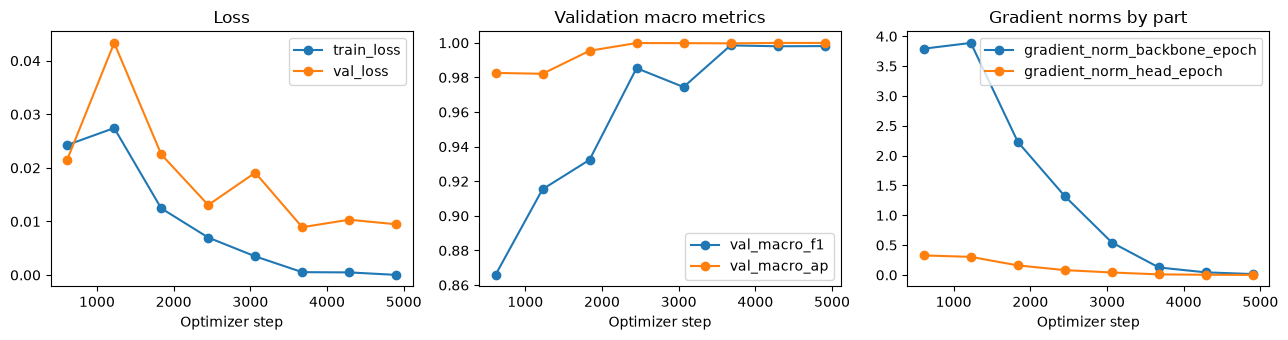

Saved curves: /Users/allakovalcuk/AI301/deep-learning-assignment2/experiments/exp5/results/bit_r50x1_fold0_seed42/curves.png
Saved gradient flow: /Users/allakovalcuk/AI301/deep-learning-assignment2/experiments/exp5/results/bit_r50x1_fold0_seed42/gradient_flow.png


In [7]:
if RUN_TRAINING:
    import csv
    import matplotlib.pyplot as plt

    with (Path(logger.log_dir) / 'metrics.csv').open(newline='') as file:
        history = list(csv.DictReader(file))
    figure, axes = plt.subplots(1, 3, figsize=(13, 3.5))
    for axis, names, title in zip(
        axes,
        (('train_loss', 'val_loss'), ('val_macro_f1', 'val_macro_ap'), ('gradient_norm_backbone_epoch', 'gradient_norm_head_epoch')),
        ('Loss', 'Validation macro metrics', 'Gradient norms by part'),
    ):
        for name in names:
            points = [(int(row['step']), float(row[name])) for row in history if row.get(name) not in (None, '')]
            if points:
                axis.plot(*zip(*points), marker='o', label=name)
        axis.set(title=title, xlabel='Optimizer step')
        if axis.lines:
            axis.legend()
    figure.tight_layout()
    curves_path = run_dir / 'curves.png'
    figure.savefig(curves_path, dpi=140)
    plt.show()
    print('Saved curves:', curves_path)
    with record_failures(run_dir, failure_configuration, 'gradient_flow', backup_failure):
        gradient_flow_path = plot_gradient_flow(run_dir / 'diagnostics' / 'layer_gradients.csv', run_dir / 'gradient_flow.png')
    print('Saved gradient flow:', gradient_flow_path)
    if drive_backup is not None:
        drive_backup.save_results([curves_path, gradient_flow_path])
else:
    print('No training curves to plot.')

## Evaluate the selected checkpoint, not the smoke test

After a complete run, reload the best checkpoint and predict all 2,452 held-out fold images in order. Report macro and per-label F1 at the fixed 0.25 threshold, average precision (which does not use the threshold), and F1 at 0.5 for context. A smoke test or stopped timing probe has no reportable score.

In [8]:
COMPLETE_RUN = RUN_TRAINING and not SMOKE_TEST and not PROFILE_ONLY and not budget_exceeded if RUN_TRAINING else False
with record_failures(run_dir, failure_configuration, 'evaluation', backup_failure):
    if COMPLETE_RUN:
        checkpoint_path = Path(checkpoint.best_model_path)
        if not checkpoint_path.is_file():
            raise FileNotFoundError(f'Missing full checkpoint: {checkpoint_path}')
        best_module = FineTuneClassifier.load_from_checkpoint(
            checkpoint_path, network=network, backbone_lr=BACKBONE_LR,
            head_lr=HEAD_LR, weight_decay=WEIGHT_DECAY, threshold=THRESHOLD,
        )
        prediction_started = time.perf_counter()
        predicted_ids, validation_probabilities = predict_probabilities(best_module, validation_loader, DEVICE)
        prediction_seconds = time.perf_counter() - prediction_started
        if predicted_ids != [row['image_id'] for row in validation_rows]:
            raise ValueError('Validation loader changed image order.')
        metrics = score_probabilities(validation_targets, validation_probabilities, THRESHOLD)
        diagnostic_metrics = score_probabilities(validation_targets, validation_probabilities, 0.5)
        print('Held-out fold metrics:', metrics)
        print('F1 at 0.5:', {'macro_f1': diagnostic_metrics['macro_f1'], 'per_label_f1': diagnostic_metrics['per_label_f1']})
    else:
        print('Full-fold evaluation skipped; smoke and timing-gate scores are not results.')

Held-out fold metrics: {'threshold': 0.25, 'macro_f1': 0.9985134806755427, 'per_label_f1': {'Cat': 0.9970472440944882, 'Dog': 0.9955201592832255, 'Moris': 1.0, 'Motya': 1.0, 'Biatrix': 1.0}, 'macro_ap': 0.9997059026730059, 'per_label_ap': {'Cat': 0.9987396836864212, 'Dog': 0.999789829678608, 'Moris': 0.9999999999999999, 'Motya': 1.0, 'Biatrix': 1.0}}
F1 at 0.5: {'macro_f1': 0.9877883526661965, 'per_label_f1': {'Cat': 0.9965534219596258, 'Dog': 0.9950199203187251, 'Moris': 0.9473684210526315, 'Motya': 1.0, 'Biatrix': 1.0}}


## Inspect where the model looks

One GradCAM overlay for the first positive validation image of each label, chosen by fold order before looking at predictions. The target is the last residual stage (`stages[-1]`), the final spatial feature map before global pooling and the 1×1 classifier. These are illustrations, not evidence that the model learned the right cue.

In [9]:
gradcam_paths = []
with record_failures(run_dir, failure_configuration, 'gradcam', backup_failure):
    if BUILD_GRADCAM and COMPLETE_RUN:
        import matplotlib.pyplot as plt
        from stage2.gradcam import gradcam_map

        output_dir = run_dir / 'gradcam'
        output_dir.mkdir(parents=True, exist_ok=True)
        best_module.to(DEVICE).eval()
        mean = torch.tensor(preprocessing['mean'])[:, None, None]
        std = torch.tensor(preprocessing['std'])[:, None, None]
        for label in LABEL_COLUMNS:
            index = next(i for i, row in enumerate(validation_rows) if row[label] == '1')
            image_id, normalized_image, _ = validation_data[index]
            heatmap = gradcam_map(best_module, normalized_image.unsqueeze(0).to(DEVICE), best_module.network.stages[-1], LABEL_COLUMNS.index(label)).cpu()
            display_image = (normalized_image * std + mean).clamp(0, 1).permute(1, 2, 0)
            figure, axis = plt.subplots(figsize=(5, 5))
            axis.imshow(display_image)
            axis.imshow(heatmap, cmap='magma', alpha=0.45, vmin=0, vmax=1)
            axis.set(title=f'{label}: {image_id}', xticks=[], yticks=[])
            path = output_dir / f'{label.lower()}_{image_id}.png'
            if path.exists():
                plt.close(figure)
                raise FileExistsError(f'Refusing to overwrite {path}')
            figure.savefig(path, dpi=140, bbox_inches='tight')
            plt.close(figure)
            gradcam_paths.append(path)
            print('Saved GradCAM:', path)
        if drive_backup is not None:
            drive_backup.save_results(gradcam_paths)
    else:
        print('GradCAM skipped.')

Saved GradCAM: /Users/allakovalcuk/AI301/deep-learning-assignment2/experiments/exp5/results/bit_r50x1_fold0_seed42/gradcam/cat_116d851cb24f39d28f719a743d10df086eb2c793.png
Saved GradCAM: /Users/allakovalcuk/AI301/deep-learning-assignment2/experiments/exp5/results/bit_r50x1_fold0_seed42/gradcam/dog_e6aea26b070dfe40f6a6121538f00cab344dc03a.png
Saved GradCAM: /Users/allakovalcuk/AI301/deep-learning-assignment2/experiments/exp5/results/bit_r50x1_fold0_seed42/gradcam/moris_055cb6e1fe1eb7fc077bd98717851ae53de3113c.png
Saved GradCAM: /Users/allakovalcuk/AI301/deep-learning-assignment2/experiments/exp5/results/bit_r50x1_fold0_seed42/gradcam/motya_cfbc890562e329131f546b43be873f41a06ad195.png
Saved GradCAM: /Users/allakovalcuk/AI301/deep-learning-assignment2/experiments/exp5/results/bit_r50x1_fold0_seed42/gradcam/biatrix_14ababeb09beeaf8dd430e851e671475ab15fc46.png


## Save the run record and held-out fold probabilities

The JSON follows the Exp1 record layout, so `08_ensemble.ipynb` can read it. Selected checkpoints for sharing go to `experiments/exp5/checkpoints/<run-id>_best.ckpt` (Git LFS); the working checkpoint stays Git-ignored in the run directory. Record the public score in the README after a manual Kaggle upload.

In [10]:
git_commit = subprocess.run(['git', 'rev-parse', 'HEAD'], cwd=ROOT, capture_output=True, text=True, check=True).stdout.strip() if (ROOT / '.git').exists() else None
source_files = (ROOT / 'notebooks' / '12_bit_resnetv2.ipynb', ROOT / 'stage2' / 'experiment.py', ROOT / 'stage2' / 'train.py', ROOT / 'stage2' / 'finetune.py', ROOT / 'stage2' / 'run_records.py', ROOT / 'stage2' / 'diagnostics.py', ROOT / 'stage2' / 'gradcam.py')
source_sha256 = {str(path.relative_to(ROOT)): file_sha256(path) for path in source_files}
with record_failures(run_dir, failure_configuration, 'results', backup_failure):
    if COMPLETE_RUN:
        probability_path = run_dir / f'{RUN_ID}_val.csv'
        record_path = run_dir / f'{RUN_ID}.json'
        for path in (probability_path, record_path):
            if path.exists():
                raise FileExistsError(f'Refusing to overwrite {path}')
        record = {**run_configuration, 'run_id': RUN_ID, 'experiment': '05_bit_resnetv2_50x1', 'status': 'completed',
                  'git_commit': git_commit, 'source_sha256': source_sha256,
                  'training': {**run_configuration['training'], 'epochs_completed': trainer.fit_loop.epoch_progress.current.completed},
                  'hardware': diagnostics.memory,
                  'trainable_parameters': sum(p.numel() for p in network.parameters() if p.requires_grad),
                  'metrics': {**metrics, 'macro_f1_at_0_5': diagnostic_metrics['macro_f1'], 'per_label_f1_at_0_5': diagnostic_metrics['per_label_f1']},
                  'timings': {'head_warmup_seconds': head_seconds, 'training_and_validation_seconds': training_seconds, 'epoch_seconds': checkpoint.epoch_seconds,
                              'first_epoch_projected_seconds': checkpoint.projected_seconds, 'best_checkpoint_prediction_seconds': prediction_seconds},
                  'artifacts': {'validation_probabilities_csv': str(probability_path.relative_to(ROOT)), 'best_checkpoint_local': str(checkpoint_path.relative_to(ROOT)),
                                'best_checkpoint_sha256': file_sha256(checkpoint_path), 'curves_csv': str((Path(logger.log_dir) / 'metrics.csv').relative_to(ROOT)),
                                'layer_gradients_csv': str((run_dir / 'diagnostics' / 'layer_gradients.csv').relative_to(ROOT)), 'gradient_flow_png': str(gradient_flow_path.relative_to(ROOT)),
                                'memory_json': str((run_dir / 'diagnostics' / 'memory.json').relative_to(ROOT)), 'gradcam_images': [str(path.relative_to(ROOT)) for path in gradcam_paths],
                                'drive_backup_dir': str(drive_backup.drive_dir) if drive_backup is not None else None},
                  'versions': {'python': platform.python_version(), 'torch': torch.__version__, 'timm': timm.__version__, 'lightning': L.__version__},
                  'telemetry': {'wandb_enabled': USE_WANDB, 'wandb_mode': WANDB_MODE if USE_WANDB else None, 'wandb_project': WANDB_PROJECT if USE_WANDB else None, 'wandb_run_id': wandb_logger.version if wandb_logger is not None else None, 'model_upload': False},
                  'public_leaderboard_score': None, 'error': None}
        write_probabilities(probability_path, predicted_ids, validation_probabilities, VALIDATION_FOLD)
        write_run_record(record_path, record)
        print('Saved:', record_path, probability_path, sep='\n')
        if drive_backup is not None:
            drive_backup.save_results([record_path, probability_path])
    else:
        print('No full-run artifacts written.')

Saved:
/Users/allakovalcuk/AI301/deep-learning-assignment2/experiments/exp5/results/bit_r50x1_fold0_seed42/bit_r50x1_fold0_seed42.json
/Users/allakovalcuk/AI301/deep-learning-assignment2/experiments/exp5/results/bit_r50x1_fold0_seed42/bit_r50x1_fold0_seed42_val.csv


## Predict the test images, if we want to ensemble

With `STAGE2_BUILD_TEST_PREDICTIONS=1`, the notebook predicts the 18,673 test images with the selected checkpoint and saves the probabilities next to the run as `<run-id>_test/`, in the same layout `08_ensemble.ipynb` reuses for Exp1 and Exp2. The Kaggle CSV is made in the next cell, from these saved probabilities.

In [11]:
if BUILD_TEST_PREDICTIONS and COMPLETE_RUN:
    with record_failures(run_dir, failure_configuration, 'test_inference', backup_failure):
        test_rows = read_csv(DATA_DIR / 'test.csv', ('image_id',))
        preflight_images(test_rows, DATA_DIR / 'test')
        test_data = ImageDataset(test_rows, DATA_DIR / 'test', IMAGE_SIZE, preprocessing['mean'], preprocessing['std'])
        test_loader = DataLoader(test_data, shuffle=False, **loader_options)
        started = time.perf_counter()
        test_ids, test_probabilities = predict_probabilities(best_module, test_loader, DEVICE)
        test_seconds = time.perf_counter() - started
        if test_ids != [row['image_id'] for row in test_rows]:
            raise ValueError('Test loader changed image order.')
        test_dir = run_dir.parent / f'{RUN_ID}_test'
        write_test_probabilities(test_dir / f'{RUN_ID}_test.csv', test_ids, test_probabilities)
        write_run_record(test_dir / f'{RUN_ID}_test.json', {
            'run_id': f'{RUN_ID}_test', 'experiment': record['experiment'], 'status': 'test_predicted', 'source_run_id': RUN_ID,
            'source_checkpoint_sha256': record['artifacts']['best_checkpoint_sha256'], 'test_images': len(test_ids),
            'transform': record['data']['transform'] + '; no test-time augmentation', 'git_commit': git_commit, 'source_sha256': source_sha256,
            'device': str(DEVICE), 'prediction_seconds': test_seconds, 'versions': record['versions'],
        })
        print(f'Saved test probabilities in {test_seconds / 60:.1f} min:', test_dir)
        print('Positives at 0.25:', {label: int((test_probabilities[:, i] >= THRESHOLD).sum()) for i, label in enumerate(LABEL_COLUMNS)})
        if drive_backup is not None:
            drive_backup.save_results(sorted(test_dir.iterdir()))
else:
    print('No test predictions built or uploaded.')

Saved test probabilities in 5.9 min: /Users/allakovalcuk/AI301/deep-learning-assignment2/experiments/exp5/results/bit_r50x1_fold0_seed42_test
Positives at 0.25: {'Cat': 7794, 'Dog': 7658, 'Moris': 147, 'Motya': 139, 'Biatrix': 165}


## Make the Kaggle submission file

With `BUILD_SUBMISSION = True` in the first code cell, this cell turns the saved test probabilities into the 0/1 CSV the competition scores. It reads `<run-id>_test/` from disk, so it works in a fresh session too: run the first code cell and the data cell, then this one, with `RUN_TRAINING = False` if you do not want to train again. It checks that the probabilities came from the run's selected checkpoint, applies the fixed 0.25 threshold, and writes the rows in `sample_submission.csv` order. It refuses to overwrite an existing file. Nothing is uploaded: upload the CSV on Kaggle by hand and note the public score.

In [12]:
if BUILD_SUBMISSION:
    import json  # Imported here so the cell works in a session that started before it was added.
    from stage2.ensemble import read_probabilities

    test_dir = ROOT / 'experiments' / 'exp5' / 'results' / f'{RUN_ID}_test'
    run_record = json.loads((ROOT / 'experiments' / 'exp5' / 'results' / RUN_ID / f'{RUN_ID}.json').read_text())
    test_record = json.loads((test_dir / f'{RUN_ID}_test.json').read_text())
    if run_record['status'] != 'completed' or test_record['source_checkpoint_sha256'] != run_record['artifacts']['best_checkpoint_sha256']:
        raise ValueError('The saved test probabilities do not come from this completed run\'s selected checkpoint.')
    submission_ids = [row['image_id'] for row in read_csv(DATA_DIR / 'test.csv', ('image_id',))]
    saved_probabilities = read_probabilities(test_dir / f'{RUN_ID}_test.csv', submission_ids)
    submission_path = ROOT / 'submissions' / f'exp5_{RUN_ID}_{round(THRESHOLD * 100):03d}.csv'
    write_submission(submission_path, form_submission(DATA_DIR / 'sample_submission.csv', submission_ids, saved_probabilities, THRESHOLD))
    submission_rows = read_csv(submission_path, ('image_id', *LABEL_COLUMNS))
    assert len(submission_rows) == len(submission_ids) and all(row[label] in ('0', '1') for row in submission_rows for label in LABEL_COLUMNS)
    print('CSV ready for manual review:', submission_path.relative_to(ROOT))
    print(f'{len(submission_rows)} rows; positives at {THRESHOLD}:', {label: sum(int(row[label]) for row in submission_rows) for label in LABEL_COLUMNS})
else:
    print('No submission CSV built or uploaded.')

CSV ready for manual review: submissions/exp5_bit_r50x1_fold0_seed42_025.csv
18673 rows; positives at 0.25: {'Cat': 7794, 'Dog': 7658, 'Moris': 147, 'Motya': 139, 'Biatrix': 165}


## Compare Exp5 with Exp3 on the test set

An ensemble only helps when its members make different mistakes, so we count how often this model and Exp3 (EfficientNetV2-S, public score 0.97015) disagree on the 18,673 test images, using the saved test probabilities and the fixed 0.25 threshold. An image counts as a disagreement if any of its five labels gets a different decision. The test labels are hidden, so this shows how different the models are, not which one is right. Exp1 (ConvNeXt) is shown as a reference, because Exp1 and Exp3 together gained +0.0075 when averaged.

The next cell shows the images with the largest probability gaps. They are the most extreme disagreements, not a random sample.

In [13]:
CURRENT = ('exp5', RUN_ID)
OTHER = ('exp3', 'efficientnetv2s_fold0_seed42')  # EfficientNetV2-S, public score 0.97015.
REFERENCE = ('exp1', 'convnext_standard_fold0_seed42_20261018_full1')  # ConvNeXt, public score 0.97003.
NAME_A, NAME_B = 'Exp5 (BiT)', 'Exp3 (EffNet)'


def load_test_probabilities(experiment: str, run_id: str, ids: list[str]) -> np.ndarray:
    results = ROOT / 'experiments' / experiment / 'results'
    run_record = json.loads((results / run_id / f'{run_id}.json').read_text())
    test_record = json.loads((results / f'{run_id}_test' / f'{run_id}_test.json').read_text())
    if run_record['status'] != 'completed' or test_record['source_checkpoint_sha256'] != run_record['artifacts']['best_checkpoint_sha256']:
        raise ValueError(f'The saved test probabilities of {run_id} do not match its completed run.')
    return read_probabilities(results / f'{run_id}_test' / f'{run_id}_test.csv', ids)


comparison_ids = [row['image_id'] for row in read_csv(DATA_DIR / 'test.csv', ('image_id',))]
probs_a = load_test_probabilities(*CURRENT, comparison_ids)
probs_b = load_test_probabilities(*OTHER, comparison_ids)
decisions_a, decisions_b = probs_a >= THRESHOLD, probs_b >= THRESHOLD
differs = decisions_a != decisions_b
differing_images = differs.any(axis=1)
named_pets = [LABEL_COLUMNS.index(label) for label in ('Moris', 'Motya', 'Biatrix')]
print(f'{NAME_A} and {NAME_B} disagree on {int(differing_images.sum())} of {len(comparison_ids)} test images ({differing_images.mean() * 100:.2f}%), in {int(differs.sum())} label cells.')
print(f'Images with a named-pet disagreement: {int(differs[:, named_pets].any(axis=1).sum())}\n')
print(f"{'label':<9}{NAME_A + ' pos':>16}{NAME_B + ' pos':>18}{'cells differ':>14}{NAME_A.split()[0] + ' only':>12}{NAME_B.split()[0] + ' only':>12}")
for index, label in enumerate(LABEL_COLUMNS):
    print(f'{label:<9}{int(decisions_a[:, index].sum()):>16}{int(decisions_b[:, index].sum()):>18}{int(differs[:, index].sum()):>14}'
          f'{int((decisions_a[:, index] & ~decisions_b[:, index]).sum()):>12}{int((decisions_b[:, index] & ~decisions_a[:, index]).sum()):>12}')
try:
    reference = load_test_probabilities(*REFERENCE, comparison_ids) >= THRESHOLD
    reference_differs = (reference != decisions_b).any(axis=1)
    print(f'\nFor reference, Exp1 (ConvNeXt) and {NAME_B} disagree on {int(reference_differs.sum())} images; '
          f'Exp1 and {NAME_A} on {int(((reference != decisions_a).any(axis=1)).sum())}.')
except FileNotFoundError:
    print('\n(No saved Exp1 test probabilities for the reference line.)')


Exp5 (BiT) and Exp3 (EffNet) disagree on 229 of 18673 test images (1.23%), in 288 label cells.
Images with a named-pet disagreement: 81

label      Exp5 (BiT) pos Exp3 (EffNet) pos  cells differ   Exp5 only   Exp3 only
Cat                  7794              7809            89          37          52
Dog                  7658              7659           113          56          57
Moris                 147               161            24           5          19
Motya                 139               129            30          20          10
Biatrix               165               181            32           8          24

For reference, Exp1 (ConvNeXt) and Exp3 (EffNet) disagree on 180 images; Exp1 and Exp5 (BiT) on 227.


Named-pet disagreements: 81 images; showing the 12 with the largest probability gap
  846d845a02c1217e5f5a41de98f558108e552e05 | Moris: Exp3 1.00 | Exp5 0.00
  67be654c331d97c24ad64f2fd33ec46b7b27e6e2 | Biatrix: Exp3 1.00 | Exp5 0.00
  4ef74744a7c637b5afc458acc87c8f3183ac57d8 | Moris: Exp3 1.00 | Exp5 0.00
  af9f94901484105af1a8ef0624a40c1f5b3a682b | Biatrix: Exp3 1.00 | Exp5 0.00
  a35bcd9ae26791c367f3a86e81e48557b3dad094 | Biatrix: Exp3 1.00 | Exp5 0.00
  4309cfb4f7d4e2019607664d3a11d713c5856358 | Motya: Exp3 0.33 | Exp5 0.00; Biatrix: Exp3 0.00 | Exp5 1.00
  ee6481a6cf08acbdaf3c1eee2633b7d8c3a5fb0d | Motya: Exp3 1.00 | Exp5 0.00
  4f4574b6771d75b017dc7318ab12b2c0c751c215 | Biatrix: Exp3 1.00 | Exp5 0.00
  acbac08c08e07d23b05996799ce75fa5504aa2f3 | Biatrix: Exp3 1.00 | Exp5 0.00
  221391c61760947e3412b2ceb1aab347859f95b3 | Biatrix: Exp3 1.00 | Exp5 0.00
  12e262e8842686035f81d17eaa818fe62ea6ebcc | Biatrix: Exp3 1.00 | Exp5 0.01
  9a4b846a2e97e3ce2e335ee2a3849e965a6afa96 | Moris: Exp3

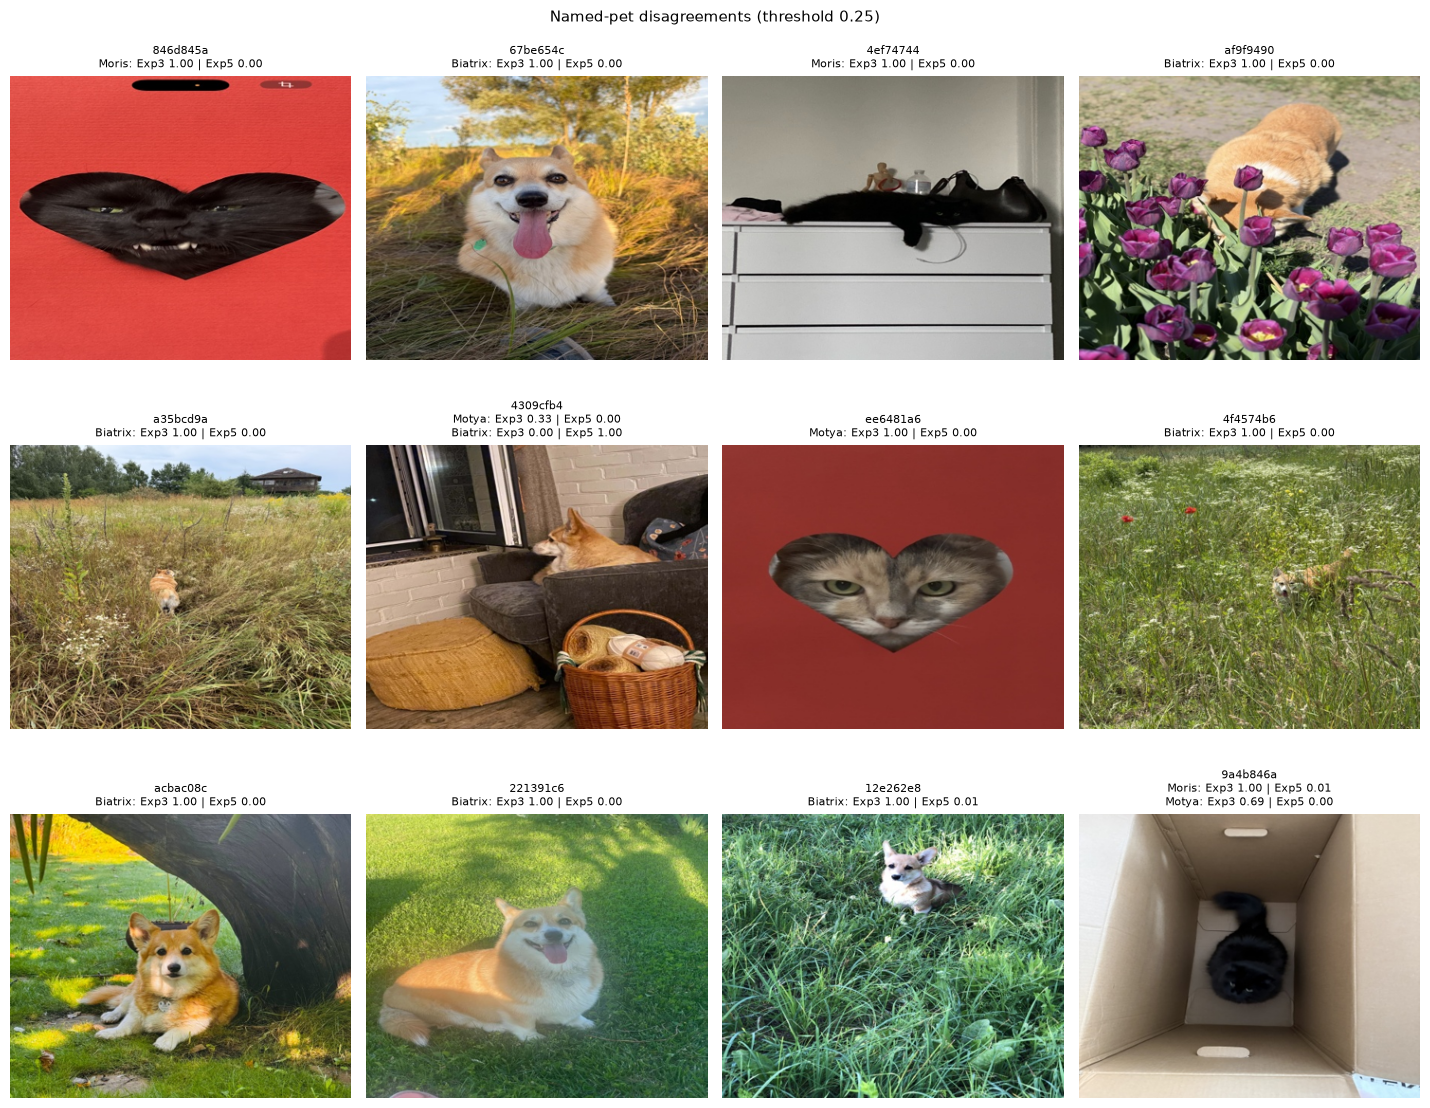

Cat and Dog disagreements: 156 images; showing the 8 with the largest probability gap
  6ffd3456a764f30a8213628a5f64c570333da8ec | Cat: Exp3 1.00 | Exp5 0.00; Dog: Exp3 0.00 | Exp5 1.00
  c0540aaa42b52d482441ad9e4214e17629aa0855 | Cat: Exp3 0.00 | Exp5 1.00; Dog: Exp3 1.00 | Exp5 0.00
  025fe0beecfb4a34d60a843307c768de6667fdc6 | Dog: Exp3 1.00 | Exp5 0.00
  0e83dc8d13b3e255e7a6d2b7849e01ee67480843 | Cat: Exp3 0.00 | Exp5 1.00; Dog: Exp3 1.00 | Exp5 0.01
  2d9fadb2f337d781a0f7cd3a7661c5bfa1c46fb3 | Cat: Exp3 0.00 | Exp5 1.00; Dog: Exp3 1.00 | Exp5 0.00
  adcc48e100b57274470fa6ffd75f808b412d91ec | Cat: Exp3 0.00 | Exp5 1.00; Dog: Exp3 1.00 | Exp5 0.00
  210490444ed99f19fd7ce9dce07f897b63844dc5 | Cat: Exp3 0.00 | Exp5 1.00; Dog: Exp3 1.00 | Exp5 0.00
  984f659392e2a225fbfb73dabf90ef19ae64d2b5 | Cat: Exp3 1.00 | Exp5 0.00


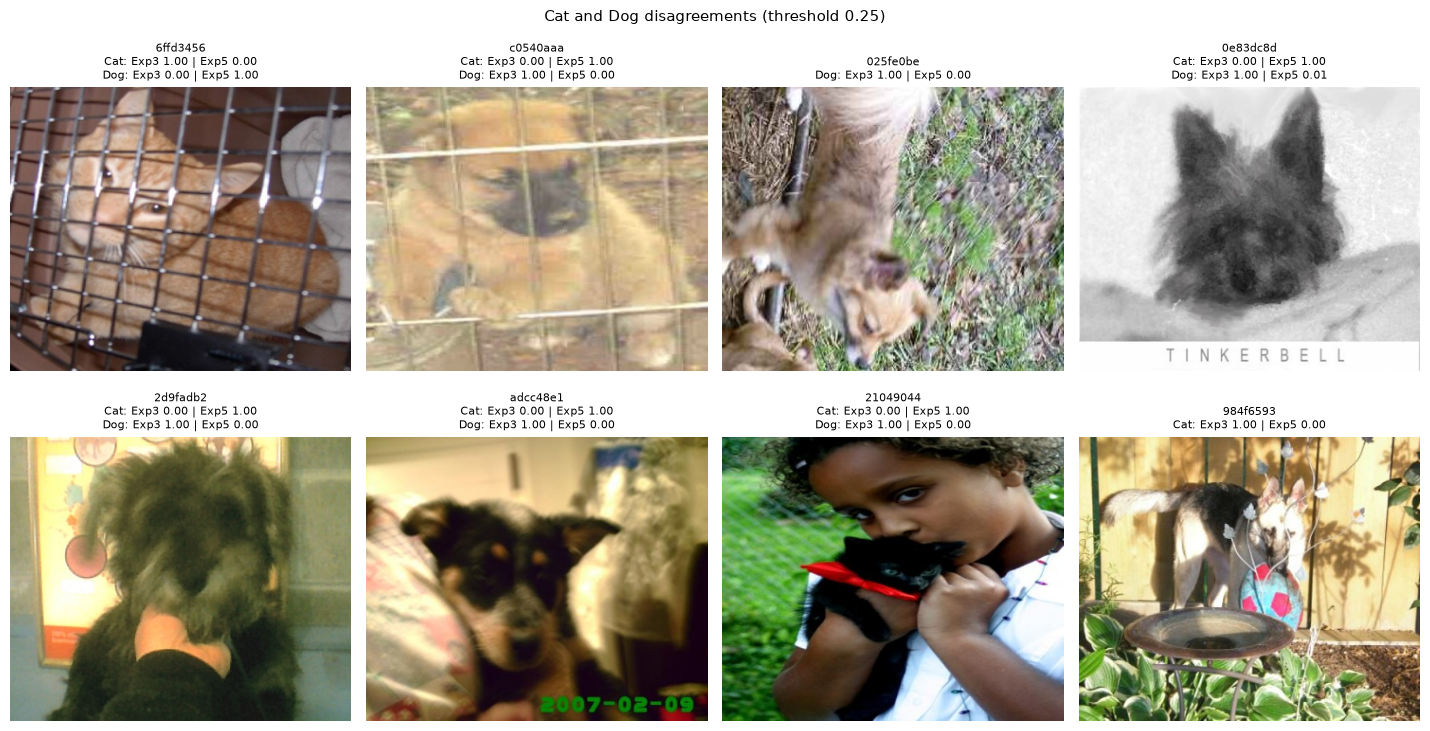

In [14]:
import matplotlib.pyplot as plt
from PIL import Image


def show_disagreements(label_indices: list[int], title: str, count: int, columns: int = 4) -> None:
    gap = np.abs(probs_a - probs_b)
    candidates = []
    for row in np.flatnonzero(differs[:, label_indices].any(axis=1)):
        cells = [index for index in label_indices if differs[row, index]]
        candidates.append((max(gap[row, index] for index in cells), int(row), cells))
    chosen = sorted(candidates, reverse=True)[:count]
    rows = -(-len(chosen) // columns)
    figure, axes = plt.subplots(rows, columns, figsize=(3.6 * columns, 3.9 * rows), squeeze=False)
    for axis in axes.ravel():
        axis.axis('off')
    print(f'{title}: {len(candidates)} images; showing the {len(chosen)} with the largest probability gap')
    for axis, (_, row, cells) in zip(axes.ravel(), chosen):
        with Image.open(DATA_DIR / 'test' / f'{comparison_ids[row]}.jpg') as photo:
            photo = photo.convert('RGB')
            photo.thumbnail((360, 360))
        axis.imshow(photo)
        lines = [f'{label}: {NAME_B.split()[0]} {probs_b[row, index]:.2f} | {NAME_A.split()[0]} {probs_a[row, index]:.2f}' for index in cells for label in (LABEL_COLUMNS[index],)]
        axis.set_title(comparison_ids[row][:8] + '\n' + '\n'.join(lines), fontsize=8)
        print(' ', comparison_ids[row], '|', '; '.join(lines))
    figure.suptitle(f'{title} (threshold {THRESHOLD})', fontsize=11)
    figure.tight_layout()
    plt.show()


show_disagreements(named_pets, 'Named-pet disagreements', count=12)
show_disagreements([LABEL_COLUMNS.index('Cat'), LABEL_COLUMNS.index('Dog')], 'Cat and Dog disagreements', count=8)


## Results and conclusions

| Model | Fold-0 macro F1 at 0.25 | Public leaderboard |
|---|---:|---:|
| Exp1: ConvNeXt-base | 0.97518 | 0.97003 |
| Exp3: EfficientNetV2-S | 0.99831 | 0.97015 |
| **Exp5: BiT ResNetV2-50x1** (this notebook) | **0.99851** | 0.94035 |
| Mean of Exp1, Exp3 and Exp5 | 0.98656 | 0.98047 |

Public scores come from the Kaggle submission list, entered by hand. Fold 0 is a screening result, not five-fold CV.

**1. BiT alone is clearly worse on the leaderboard.** 0.94035 is 0.030 below Exp3 and 0.058 below its own fold-0 score. The fold-0 score (perfect on all three pets) did not predict it; each pet has only 8–10 photos on fold 0, and the checkpoint was chosen there.

**2. Where it differs from the other models.** On the test set BiT and Exp3 disagree on 229 of 18,673 images (1.23%), more than Exp3 and Exp1 disagree (180), so BiT is the most different member. It predicts fewer Moris and Biatrix than Exp3 (147 and 165 against 161 and 181) and more Motya (139 against 129). In the largest disagreements BiT says 0.00 for photos that look like the named pets (a corgi outdoors, black cats), often with the animal small in the frame. We could not check this against the hidden labels.

**3. It is still useful in the mean.** Added to Exp1 and Exp3 it raised the public score from 0.97761 to 0.98047 (see `13_ensemble_exp1_exp3_exp5.ipynb`), because its vote settles cells where the other two disagree. A member that is weak alone can help an ensemble when its mistakes differ from the others'.

**4. How the run went.** The full run took 2.1 hours on the Mac GPU: 30 minutes for the head warm-up (best held-out macro F1 0.954) and 94 minutes for the fine-tune, at 11.8 minutes per epoch, faster than the 13.8 minutes a short probe projected. The best checkpoint came at epoch 6. BiT's validation loss was the highest of our runs (0.0095 against about 0.003 for ConvNeXt and 0.0065 for EfficientNet), and its fold-0 F1 drops from 0.99851 at threshold 0.25 to 0.98779 at 0.5 (Moris 0.947), so its probabilities are less saturated and more sensitive to the threshold.

**Limits and ideas.** One seed and one fold, untuned learning rates (`3e-5` backbone, `3e-4` head), flip-only augmentation and no ablation. Untested explanations for the weak test score: the pets are small in the frame and we used 384 pixels instead of the native 448, the learning rates were too low to adapt the backbone, or the fold-0 checkpoint selection was lucky. Running BiT at 448 would test the first one.